# conv_02 — 코어 기준 격자와 원인 판정 규칙

conv_01 에서 "시간이 아니라 카운트로 본다", "카운터 리셋으로 모든 엣지를 복원한다"를 확인했다.
여기서는 그 위에 **코어 기준 격자**를 세우고, 센서 신호가 달라졌을 때 **무엇이 원인인지 가르는 규칙**을 정리한 뒤 40일(09-10 – 10-19)에 적용한다.

| 자료 | 위치 |
|---|---|
| 이벤트·일별 표·판정 함수 | `Conv/conv_grid.py` (`day_events`, `daily_table`, `judge`, `sensor_level`, `wagon_level`) |
| 카운터·위치 함수 | `Conv/conv_core.py` |
| 대차×센서 일별 표 (캐시) | `cache/conv_feat/wagon_sensor_daily.pkl` |
| 판정 결과 (캐시) | `cache/conv_feat/wagon_sensor_judged.pkl` |

## 결론 요약

| 항목 | 결과 |
|---|---|
| 코어 센서 | **대차 진입·쉬프트·클로징·오프닝·후진 진입 5개.** 대차에 무관하게 같은 자리에서 켜지고(대차 간 차이 ±1), 켜짐 길이는 모든 대차 8카운트(0.72초) |
| 전진 진입 | 코어가 아니다. 대차마다 켜지는 위치·길이가 다르고, 대차 안 흔들림도 코어의 몇 배 (§3) |
| 원인 | 카운터는 서로 독립이라 다른 센서 탓이 아니다. **한 대차에서 두 번 켜지거나(2차 리셋, 통과당 0.35번)** "일찍 켜진 만큼 길게 켜짐" = 대차의 정상 표식 앞에 이물이 있음 (§0-3, §4) |
| 40일 사건 | 전진: 이물이 생기고 사라지는 대차가 여럿 (청소로 보이는 복귀 포함). 후진 28번: 09-10 이물 → **09-22 복귀**. 오프닝 20번: 40일 내내 이물 (§5, §6) |
| 센서 단위 | **후진 진입 센서의 위치가 0 → +3.5 → +1 → +3.5 → 0 으로 왔다 갔다**, 흔들림 큰 날 사흘 → 브래킷 고정 점검 후보. 나머지 코어 4개는 40일간 위치 변화 0 (§7) |
| 대차·라인 단위 | 대차 표식 이동 0건, 속도 비율 −0.12 – +0.07% (허용 ±0.3%) — 이상 없음 (§7) |
| 공정 영향 | 전진 유닛 원점 확인 에러 97회 중 93회는 정지·기동 중 발생. 이물 대차와 관계 없음 → **지금 수준의 이물은 "점검 추천" 단계** (§8) |

---
## §0. 정리

### 0-1. 대차 ID 와 "같은 대차" 맞추기

**대차 ID = 그 대차가 대차 진입 센서(P00140)를 지날 때의 메인 대차번호.** 이후 모든 표의 `wagon` 은 이 번호다.

> conv_01 과 앞선 대화의 대차번호는 "센서가 켜진 순간의 메인 대차번호"였다. 센서마다 일정한 칸만큼 밀려 있어서 여기 번호와 다르다.

센서 X 의 엣지가 어느 대차의 것인지는 **같은 대차가 P00140 을 지난 엣지**를 찾아서 정한다. 이때 쓰는 값이 둘이다.
- **n_back:** 센서 X 가 P00140 에서 대차 몇 대 뒤에 있는지
- **dist:** 그 대차가 P00140 에서 X 까지 가는 동안의 카운트 = 센서 간 고정 거리 + 그 대차·센서의 고유 오프셋

"가장 가까운 P00140 엣지"를 자로 쓰면 안 된다. 두 센서 앞에 있는 대차가 서로 다르기 때문이다. 그 사이에 간격 넓은 대차(피치 142–143, 6대 연속)가 몇 대 끼느냐에 따라 값이 최대 약 22카운트 밀린다.

**n_back 정하는 법**

| 센서 | n_back | 정한 방법 |
|---|---|---|
| 대차 진입 P00140 | 0 | 1번 대차 감지 P00142 |
| 전진 진입 P00451 | 26 | **1번 대차 감지 P00450** — 1번 대차가 전진 유닛에 올 때 메인 번호가 항상 27 (1,043회 모두) |
| 후진 진입 P00459 | 41 | 1번 대차 감지 P00458 — 항상 42 (1,095회 모두). 패턴 매칭 결과(41)와 일치 → 방법 검증 |
| 대차 쉬프트 P00141 / 클로징 P00154 / 오프닝 P00164 | 0 / 2 / 26 | 패턴 매칭: 0–41 을 모두 시도해 대차별 dist 가 ±2 안에 드는 비율이 가장 큰 값. 31 가동일 모두 같아서 고정값으로 둔다 |

전진 진입은 어떤 n 을 넣어도 대차 절반 정도만 ±2 안에 든다(대차마다 위치가 정말 다르다). 그래서 **반드시 1번 대차 감지 센서로 정해야** 한다.

### 0-2. 펄스 하나에서 읽는 값

```
           앞 끝(rise)                뒤 끝(fall)
  카운터 리셋 → 정확 (1카운트)        원본 비트 하강 → ±0.5초 오차 (하루 대차당 약 60번 중앙값으로 평균)
               │◀────── 켜짐 길이 (width) ──────▶│
  ─────────────┴─────────────────────────────────┴──────▶ 카운트
```

| 값 | 뜻 | 정상 기준 |
|---|---|---|
| `rise_off` 앞 끝 편차 | 같은 대차의 dist − 그 센서 대차 대부분의 dist | 0 |
| `width_ex` **이물 지수** | 켜짐 길이 − 그 센서의 정상 켜짐 길이 (W0, 대차 중앙값) | 0 |
| `fall_off` 뒤 끝 편차 | rise_off + width_ex | 0 |
| `jitter` 흔들림 | 같은 대차 하루 dist 의 IQR | 코어 0–1 |
| `pitch` 피치 | 앞 대차와의 간격 | 대차별 고정 (체인 간격) |
| `D` 센서 간 거리 | 그 센서 대차 중앙 dist | 날마다 같아야 함 |

**정상 기준을 과거 평균이 아니라 "그날 그 센서에서 대차 대부분이 보이는 값"으로 잡는다.** 깨끗한 표식은 모두 같은 길이·같은 자리로 보이기 때문이다. 그래서 청소하면 이물 지수는 0 으로 돌아가고, 모델은 그걸 이상으로 보지 않는다.

### 0-3. 판정 규칙

**① 칸 단위 (대차 × 센서 × 날짜)** — `classify_cell`

| 순서 | 조건 | 상태 | 해석 |
|---|---|---|---|
| 0 | 대차 한 번 지날 때 **2차 리셋**이 평균 0.5번 이상 | **이물(분리)** | 센서가 한 대차에서 두 번 켜짐: **떨어져 있는 이물**에 한 번, 원래 표식에 한 번 (또는 채터링) |
| 1 | 이물 지수 ≥ 3, 앞 끝이 그만큼 당겨짐 (rise_off ≤ −(이물 지수 − 2)) | **이물(앞)** | 표식 **앞**에 붙은 무언가 (돌출·찌꺼기). 뒤 끝은 제자리 |
| 2 | 이물 지수 ≥ 3, 앞 끝 제자리 (\|rise_off\| < 2) | **이물(뒤)** | 표식 **뒤**에 무언가 |
| 3 | 이물 지수 ≥ 3, 그 밖 | 이물(기타) | 길이도 길고 위치도 다름 |
| 4 | 길이 정상, 앞·뒤 끝이 같이 허용폭 이상 이동 | **위치 변화** | 표식·부품 자체가 옮겨짐 (브래킷 휨 등) |
| 5 | 그 대차만 흔들림이 허용폭 이상 | **흔들림** | 그 대차 표식이 헐거움 |
| 6 | 그 밖 | 정상 | |

**2차 리셋.** 대차가 지나가는 중에 센서가 꺼졌다 다시 켜지면 PLC 는 카운터를 다시 1 로 리셋한다. DB 에서는 카운터가 조금(50 미만) 떨어지는 것으로 보인다. 원본 비트로는 0.5초 샘플 사이에 묻히지만 카운터에는 남는다. 코어 센서는 통과당 0.00 – 0.02 번, 전진 진입은 0.35 번이다.
- PLC 는 **마지막** 상승엣지로 카운터를 맞추므로 스톱퍼는 원래 표식 기준으로 나간다 (conv_03 에서 확인). 그래서 지금 이물은 유닛 동작에 영향이 작다.

**물리 기준은 깨끗한 대차로 잡는다.** 재감지가 적고(통과당 < 0.25) 켜짐 길이가 정상(±1.5)인 대차의 중앙값이 D·W0 다. 전진 진입처럼 이물 대차가 많은 센서에서 전체 중앙값을 쓰면 기준이 일찍 켜지는 쪽으로 끌려간다.

허용폭: 앞·뒤 끝 = max(3, 1.5 × 그 센서의 평소 흔들림 J0), 흔들림 = max(3, 2 × J0). 코어는 J0 ≈ 0 이라 3 그대로. 전진은 J0 가 3–4 라서 5–6 으로 넓어진다.

**② 시간 규칙 (같은 대차·센서의 날짜 순서)** — `judge`

| 사건 | 조건 | 모델 동작 |
|---|---|---|
| **새 이물** | 전날 이물이 아니었는데 오늘 이물 | 경고 (대차번호·센서·시작일) |
| **이물 복귀** | 전날 이물이었는데 오늘 이물 지수 < 1.5 | **경고 없음.** 청소·제거로 기록 |
| **위치 변화 점검** | 새 위치가 처음 보임 | 점검 알림 1회 |
| **위치 승인** | 같은 위치가 가동일 n=3 일 유지 | 그 대차·센서의 단기 기준을 새 위치로 갱신, 이후 경고 없음 |
| 위치 복귀 | 승인했던 위치에서 원래 자리(정상)로 돌아옴 | 기록만 |
| 흔들림 | 처음 흔들림 | 점검 알림 |

이물은 **절대 자동 승인하지 않는다.** 3일 넘게 붙어 있어도 오염은 오염이다. 위치 변화만 n일 뒤 새 정상으로 받아들인다.

**③ 센서 단위** — `sensor_level`
- 한 센서에서 대차 절반 이상이 같은 상태면 그 센서 자체의 문제로 올린다. 예: 모든 대차가 길게 켜지면 센서 면 오염.
- 장기 기준(09-10 – 09-19)과 비교해 아래 셋을 본다.
  - **D 변화:** 센서 이동 (이 센서만 변한 경우)
  - **W0 변화:** 센서 감도·센서 면 오염
  - **J0 변화:** 센서 고정 불량·진동

**④ 대차 단위** — `wagon_level`
- 코어 센서 3개 이상에서 그 대차의 피치가 장기 기준과 2 이상 다르면 **대차 체인 표식(dog) 이동**이다.
- 대차 표식이 옮겨지면 같은 대차끼리 잰 dist 는 그대로다(모든 센서에서 같이 밀리므로). 대신 앞뒤 대차와의 간격이 바뀌므로 피치로 잡는다.

**⑤ 라인 단위**
- **속도 비율** (초당 카운트 ÷ Hz/10)이 0.2744 에서 0.3% 넘게 벗어나면 구동부·체인 미끄러짐이다 (conv_01).
- 모든 센서의 D 가 같은 비율로 변하면 체인 늘어남이다. 엔코더가 체인 스프로킷 축에 있다는 가정이고, 장기 추세로만 본다.

**⑥ 기준 두 개**

| 기준 | 갱신 | 용도 |
|---|---|---|
| 물리 기준 (그날 센서 대차 대부분) | 매일 | 이물·위치·흔들림 판정의 0점 |
| 단기 기준 (승인된 위치) | 위치 변화가 n일 유지되면 | 같은 변화로 경고가 반복되지 않게 |
| 장기 기준 (09-10 – 09-19 고정) | **갱신 안 함** | 3일 단위로는 안 보이는 느린 변화 (센서 거리·감도·흔들림·피치·속도) |

### 0-4. 원인 판별표 — 무엇이 보이면 무엇을 의심하나

| 보이는 것 | 범위 | 의심 원인 | 권장 조치 | 자동 승인 |
|---|---|---|---|---|
| 한 대차에서 두 번 켜짐 (2차 리셋) | 대차 1대 × 센서 1개 | 표식 앞 **떨어진 이물**·채터링 | 그 대차 해당 위치 확인·청소 | 안 함 |
| 한 대차에서 두 번 켜짐 | 센서 1개, 대차 여럿 (통과당 ≥ 0.1) | **센서 채터링**·감지 거리 과다 | 센서 감지 거리·고정 확인 | 안 함 |
| 켜짐 길이 ↑ + 앞 끝만 당겨짐 | 대차 1대 × 센서 1개 | 그 대차, 그 센서가 보는 부분 **앞쪽 이물·돌출** | 그 대차 해당 위치 확인·청소 | 안 함 |
| 켜짐 길이 ↑ + 뒤 끝만 늘어남 | 대차 1대 × 센서 1개 | 뒤쪽 이물 | 같음 | 안 함 |
| 켜짐 길이 ↑ | 센서 1개, 대차 대부분 (W0 ↑) | **센서 면 오염**·감도 변화 | 센서 청소 | 안 함 |
| 길이 정상 + 앞뒤 같이 이동 | 대차 1대 × 센서 1개 | 그 대차의 표식·부품 위치 변화 | 점검 1회 | n일 유지 시 |
| D 변화 (모든 대차 같이) | 센서 1개 | **센서 브래킷 이동** | 센서 위치 점검 | n일 유지 시 (장기 기록은 유지) |
| 흔들림 ↑ | 대차 1대 | 그 대차 표식 헐거움 | 대차 점검 | 안 함 |
| 흔들림 ↑ (J0 ↑) | 센서 1개, 대차 대부분 | **센서 고정 불량**·진동 | 센서 고정 확인 | 안 함 |
| 피치 변화 | 대차 1대 × 코어 3개 이상 | **대차 체인 표식(dog) 이동** | 대차 점검 | n일 유지 시 |
| 속도 비율 변화 > 0.3% | 라인 전체 | 구동부·체인 미끄러짐 | 구동부 점검 | 안 함 |
| 모든 센서 D 비례 변화 | 라인 전체 (장기) | 체인 늘어남 (가정) | 장기 추세 | 장기 기준 고정 |
| 이물 지수 → 0 | — | 청소·제거 | 기록만 | — |

**판정 기준값과 근거**

| 이름 | 값 | 근거 |
|---|---|---|
| `REARM_TOL` 재감지 | 통과당 0.5 번 | 코어 센서 0.00 – 0.02. 이물 대차는 0.8 – 1.7 |
| `SENSOR_REARM_TOL` 센서 재감지 | 통과당 0.1 번 (센서 전체) | 전진 진입 0.35, 나머지 ≤ 0.02 |
| `W_TOL` 이물 | 3카운트 | 코어 센서의 대차 간 켜짐 길이 차이 std 0.6–0.7 → 4–5σ |
| `T_TOL` 위치 | 3 (센서 흔들림에 비례해 넓힘) | 코어 대차 간 위치 차이 ±1 |
| `J_TOL` 흔들림 | 3 (센서 흔들림 2배까지 넓힘) | 코어 대차 안 IQR 0–1 |
| `BACK_TOL` 복귀 | 1.5 | 이물 지수가 정상 범위 안으로 |
| `N_ACCEPT` 승인 | 가동일 3일 | §6 위치 변화 지속 기간 분포 참고 |
| `SPEED_TOL` 구동부 | 0.3% | 속도 비율의 일별 흔들림 0.05%의 6배 |

### 0-5. 센서 종류와 근접 센서의 동작 — 무엇을 보는 센서인가

PLC 태그 이름 끝에 센서 종류가 붙어 있다. **PX = 근접 센서, CS = 실린더 스위치.**

| 센서 | 예 (전진 유닛) | 종류 | 무엇을 보나 | 이 노트북 규칙 적용 |
|---|---|---|---|---|
| **대차 통과 센서** | 진입 감지 P00451 (`In_CHK_PX`), 대차 진입 P00140, 쉬프트 P00141, 오프닝·클로징 진입, 1번 대차 감지 P00142·P00450·P00458 | 근접 (유도형, 금속 감지) | 고정된 자리에서 **지나가는 대차의 금속 표식(dog)** | **적용** — 켜짐 길이 ≈ 8카운트가 정상, 타이밍과 이물 지수로 평가 |
| 유닛 위치 센서 | 정위치 P00452 (`ORG_PX`), 끝단 후진 P00453 (`Rev_PX`), 비상 P00454 (`Rev_FLT_PX`) | 근접 | **유닛 자신의 이동대**가 레일 위 어디 있는지 (스톱퍼가 대차를 잡으면 유닛이 끌려갔다가 돌아온다) | 적용 안 함 → 시퀀스 타이밍 (conv_03) |
| 실린더 스위치 | 스톱퍼 전진·후진 감지 P00455·P00456, 노즐 후진 감지 P00457 (`Stopper_FWD_CS`, `Nozzle1_REV_CS`) | 자석 감지 (실린더 피스톤 속 자석) | **실린더가 끝까지 갔는지** | 적용 안 함 → 시퀀스 타이밍 (conv_03) |

- 대차 쪽에는 센서가 없다. 센서는 전부 라인·유닛 쪽에 있고, 대차에는 감지되는 금속만 있다.
- 유닛 위치 센서와 실린더 스위치는 "그 상태인 동안" 켜져 있으므로 켜짐 길이 8 이 성립하지 않는다.
- 정확한 센서 모델은 현장 확인 필요. 태그 이름과 `kta 자료_센서위치.pdf` 사진 기준이다.

**대차마다 금속이 하나이고 모든 센서가 그걸 같이 보나? — 아니다 (§3-2).**
- 이물은 항상 **센서 한 곳에서만** 보인다. 오프닝 20번 대차의 이물은 대차 진입·쉬프트·클로징·후진에서 0% 다.
- 모든 센서가 같은 금속을 본다면 그 앞의 이물도 모든 센서에서 보여야 한다. 그러니 위치마다 대차의 **다른 표식(높이·방향이 다른 금속)** 이나 **같은 표식의 다른 면**을 본다.
- 1번 대차에는 1번 감지 센서용 표식이 하나 더 있다 (P00142 는 1번 대차에서만 켜진다).
- 그래서 판정 단위는 "대차"가 아니라 **"대차 × 센서" 칸**이다.

**근접 센서 패턴 → 원인**

유도형 근접 센서는 금속과의 **간격**에 따라 켜지는 범위가 달라진다. 앞 끝·뒤 끝이 어떻게 움직였는지로 원인을 가른다.

| 패턴 | 원인 | 지금 판정 코드 |
|---|---|---|
| 한 대차에서 **두 번 이상 켜짐** (2차 리셋) | 표식 앞에 **떨어져 있는** 금속·이물, 또는 채터링 | **이물(분리)** |
| 앞 끝만 당겨짐, 뒤 끝 제자리, 길이 ↑ | 표식 **앞쪽**에 붙은 금속·이물 | **이물(앞)** |
| 뒤 끝만 늘어남, 앞 끝 제자리, 길이 ↑ | 표식 **뒤쪽**에 이물 | **이물(뒤)** |
| 앞뒤가 **양쪽으로 같이** 늘어남 | 표식이 센서에 **가까워짐** (대차 흔들림·브래킷 휨·센서가 밀려 들어감) | 지금은 "이물(기타)" 에 섞여 있음 → **감지 간격 변화(가까워짐)** 로 분리 예정 |
| 앞뒤가 양쪽으로 줄어듦, 심하면 놓침 | 표식이 **멀어짐** (센서 브래킷이 헐거워 밀림) | **아직 안 봄** → 감지 간격 변화(멀어짐) 로 추가 예정. 놓침은 카운터 존 미감지 에러(160)로도 잡힘 |
| 길이 정상, 앞뒤가 같이 이동 | 표식·부품 **위치** 변화 | **위치 변화** |
| 한 센서의 모든 대차에서 위 패턴 | 대차가 아니라 **센서 쪽** (센서 면 오염·센서 위치·고정) | 센서 단위 판정 (§7) |

---
## §1. 준비

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib, matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap, BoundaryNorm

ROOT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..") if os.path.basename(os.getcwd()) == "Conv" else os.getcwd())
CONV_DIR = os.path.join(ROOT_DIR, "Conv")
for p in (ROOT_DIR, CONV_DIR):
    if p not in sys.path:
        sys.path.insert(0, p)
matplotlib.rcParams["font.family"] = "AppleGothic"
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
warnings.simplefilter("ignore", RuntimeWarning)

from conv_core import load_group, add_position, K_SPEED
from conv_grid import (SENSORS, day_events, daily_table, judge, sensor_level, wagon_level,
                       W_TOL, T_TOL, J_TOL, BACK_TOL, N_ACCEPT, SPEED_TOL)

START, END = "2026-09-10", "2026-10-19"
LONG_REF = ("2026-09-10", "2026-09-19")          # 장기 기준 (가동 8일)
DEMO_WEEK = ("2026-10-13", "2026-10-17")
FEAT_DIR = os.path.join(ROOT_DIR, "cache", "conv_feat")
DAILY_PATH = os.path.join(FEAT_DIR, "wagon_sensor_daily.pkl")
JUDGED_PATH = os.path.join(FEAT_DIR, "wagon_sensor_judged.pkl")

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, CRITICAL = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"
PURPLE, YELLOW = "#7a5cc7", "#c99a06"
CORE = SENSORS.index[SENSORS.core].tolist()
NAME = SENSORS.name.to_dict()
ORDER = ["P00140", "P00141", "P00154", "P00164", "P00451", "P00459"]     # 루프 순서 (P00140 기준 거리)

STATES = ["정상", "흔들림", "위치 변화", "이물(뒤)", "이물(기타)", "이물(앞)", "이물(분리)"]
STATE_COLOR = {"정상": "#ebeae4", "흔들림": YELLOW, "위치 변화": PURPLE,
               "이물(뒤)": AQUA, "이물(기타)": ORANGE, "이물(앞)": CRITICAL, "이물(분리)": "#8a2a5c"}


def style_ax(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=INK2, labelsize=8)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)


SENSORS

,name,group,counter,core,first,n_fix
bit,,,,,,
P00140,대차 진입,main,R00040,True,P00142,0
P00141,대차 쉬프트,main,R00080,True,NaN,0
P00154,클로징 진입,closing,R00030,True,NaN,2
P00164,오프닝 진입,opening,R00070,True,NaN,26
P00451,전진 진입,md_fwd,R00055,False,P00450,26
P00459,후진 진입,md_rev,R00060,True,P00458,41


In [2]:
# 대차×센서 일별 표 — 없으면 40일을 새로 만든다 (약 20초)
if os.path.exists(DAILY_PATH):
    daily = pd.read_pickle(DAILY_PATH)
else:
    parts = []
    for d in pd.date_range(START, END).strftime("%Y-%m-%d"):
        ev = day_events(d)
        if len(ev):
            parts.append(daily_table(ev))
    daily = pd.concat(parts)
    daily.to_pickle(DAILY_PATH)

daily = daily[daily.n >= 20]                       # 대차당 하루 20번 미만(거의 안 돈 날)은 뺀다
judged = judge(daily)
judged.to_pickle(JUDGED_PATH)
print(f"가동일 {judged.day.nunique()}일 · 센서 {judged.sensor.nunique()}개 · 대차 {judged.wagon.nunique()}대 · 칸 {len(judged):,}")

가동일 31일 · 센서 6개 · 대차 42대 · 칸 7,812


---
## §2. 루프 지도 — 센서들은 체인 위 어디에 있나

P00140 을 0 으로 놓고, 같은 대차가 각 센서에 닿기까지의 카운트(D). 한 바퀴는 피치 합 약 5,860카운트다.

In [3]:
lap = daily[daily.sensor == "P00140"].groupby("day").pitch.sum().median()
loop = (judged.groupby("sensor").agg(D=("D", "median"), D_min=("D", "min"), D_max=("D", "max"),
                                     W0=("W0", "median"), J0=("J0", "median"))
        .reindex(ORDER))
loop.insert(0, "이름", [NAME[s] for s in loop.index])
loop.insert(1, "n_back", SENSORS.loc[loop.index, "n_fix"].to_numpy())
loop["대차 몇 대 뒤"] = (loop.D / (lap / 42)).round(1)
print(f"한 바퀴 ≈ {lap:.0f} 카운트")
loop

한 바퀴 ≈ 5850 카운트


,이름,n_back,D,D_min,D_max,W0,J0,대차 몇 대 뒤
sensor,,,,,,,,
P00140,대차 진입,0,0.0,0.000,0.0,8.0,0.000,0.0
P00141,대차 쉬프트,0,19.0,19.000,19.0,8.0,0.000,0.1
P00154,클로징 진입,2,295.0,295.000,295.0,8.5,0.000,2.1
P00164,오프닝 진입,26,3709.0,3709.000,3709.0,8.5,0.000,26.6
P00451,전진 진입,26,3752.5,3751.500,3754.5,9.0,3.625,26.9
P00459,후진 진입,41,5725.5,5722.875,5728.0,8.0,0.500,41.1


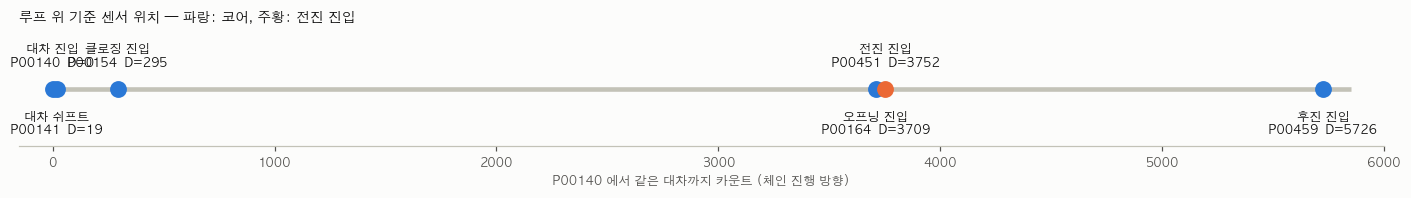

In [4]:
fig, ax = plt.subplots(figsize=(13, 1.9), facecolor=SURFACE)
ax.hlines(0, 0, lap, color=AXIS, lw=3)
for i, s in enumerate(ORDER):
    x = loop.loc[s, "D"]
    c = ORANGE if s == "P00451" else BLUE
    ax.plot(x, 0, "o", ms=10, color=c, zorder=3)
    ax.annotate(f"{NAME[s]}\n{s}  D={x:.0f}", (x, 0), xytext=(0, 14 if i % 2 == 0 else -30),
                textcoords="offset points", ha="center", fontsize=8, color=INK)
ax.set_xlim(-150, lap + 150)
ax.set_ylim(-1, 1)
ax.set_yticks([])
style_ax(ax, grid=None)
ax.spines["left"].set_visible(False)
ax.set_xlabel("P00140 에서 같은 대차까지 카운트 (체인 진행 방향)", color=INK2, fontsize=8)
ax.set_title("루프 위 기준 센서 위치 — 파랑: 코어, 주황: 전진 진입", color=INK, fontsize=9, loc="left")
plt.tight_layout()
plt.show()

대차 진입·쉬프트·클로징은 P00140 근처(0–2대)에, 오프닝과 전진은 26대 뒤에, 후진은 41대 뒤(한 바퀴 거의 끝)에 있다.
오프닝과 전진은 42카운트 차이로 붙어 있는데 하나는 코어이고 하나는 아니다. **위치 때문이 아니라 센서 자체(설치·감지 대상)의 차이**라는 뜻이다.

---
## §3. 코어 격자 확인 — 대차별 위치와 켜짐 길이

한 주(10-13 – 10-17) 중앙값. 행 = 센서, 열 = 대차 ID. 코어 5개는 거의 한 색이어야 한다.

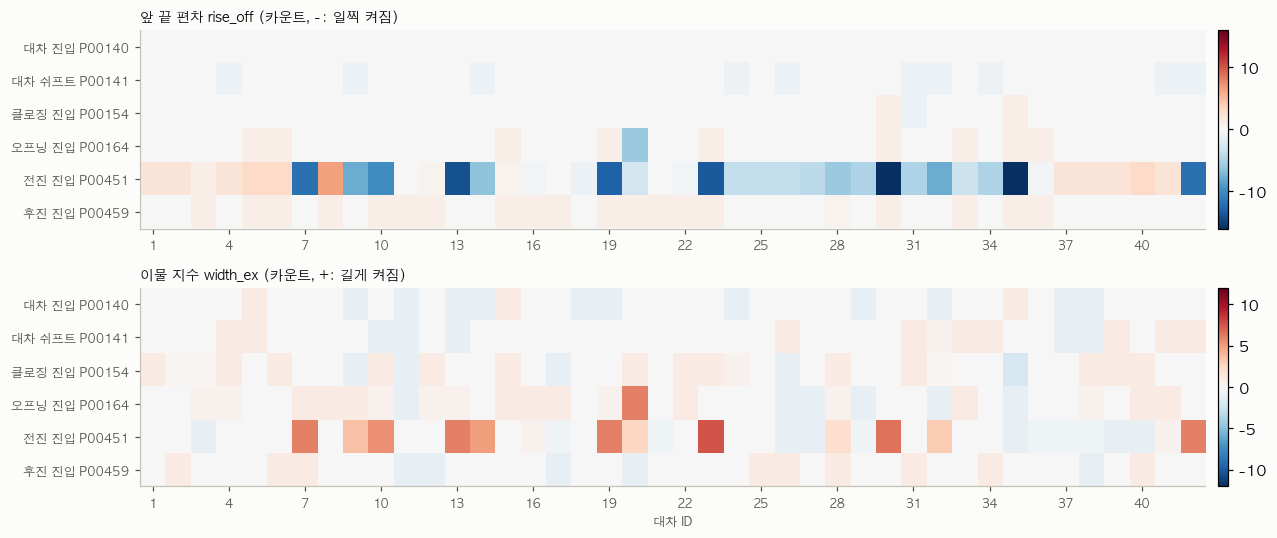

,이름,대차간_위치차_std,대차간_길이차_std,대차안_흔들림,켜짐길이
sensor,,,,,
P00140,대차 진입,0.00,0.55,0.0,8.0
P00141,대차 쉬프트,0.43,0.63,0.0,8.0
P00154,클로징 진입,0.28,0.77,0.0,8.0
P00164,오프닝 진입,1.04,1.08,0.0,8.0
P00451,전진 진입,5.94,2.91,3.5,9.0
P00459,후진 진입,0.76,0.80,0.5,8.0


In [5]:
wk = judged[(judged.day >= DEMO_WEEK[0]) & (judged.day <= DEMO_WEEK[1])]
fig, axes = plt.subplots(2, 1, figsize=(13, 5.0), facecolor=SURFACE)
for ax, col, ttl, lim in [(axes[0], "rise_off", "앞 끝 편차 rise_off (카운트, -: 일찍 켜짐)", 16),
                          (axes[1], "width_ex", "이물 지수 width_ex (카운트, +: 길게 켜짐)", 12)]:
    m = wk.pivot_table(index="sensor", columns="wagon", values=col, aggfunc="median").reindex(ORDER)
    im = ax.imshow(m.to_numpy(), aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_yticks(range(len(ORDER)), [f"{NAME[s]} {s}" for s in ORDER], fontsize=8)
    ax.set_xticks(range(0, 42, 3), [str(w) for w in m.columns[::3]], fontsize=7)
    ax.set_title(ttl, color=INK, fontsize=9, loc="left")
    style_ax(ax, grid=None)
    fig.colorbar(im, ax=ax, pad=0.01)
axes[1].set_xlabel("대차 ID", color=INK2, fontsize=8)
plt.tight_layout()
plt.show()

core_stat = wk.groupby("sensor").agg(대차간_위치차_std=("rise_off", "std"), 대차간_길이차_std=("width_ex", "std"),
                                     대차안_흔들림=("jitter", "median"), 켜짐길이=("W0", "median")).reindex(ORDER).round(2)
core_stat.insert(0, "이름", [NAME[s] for s in core_stat.index])
core_stat

### §3-2. 이물은 센서 한 곳에서만 보인다

이물이 있는 대차를 골라, 같은 대차가 다른 센서에서는 어떻게 보이는지. 값은 40일 중 이물 판정 비율(%).

In [6]:
picks = [(20, "P00164"), (13, "P00451"), (14, "P00451"), (19, "P00451"), (28, "P00459")]
rows = []
for w, first in picks:
    g = judged[judged.wagon == w].groupby("sensor").state.apply(lambda x: x.str.startswith("이물").mean() * 100)
    rows.append(g.reindex(ORDER).rename(f"{w}번 (처음 본 센서: {NAME[first]})"))
loc = pd.DataFrame(rows).round(0)
loc.columns = [f"{NAME[s]}" for s in loc.columns]
loc

,대차 진입,대차 쉬프트,클로징 진입,오프닝 진입,전진 진입,후진 진입
20번 (처음 본 센서: 오프닝 진입),0.0,0.0,0.0,100.0,65.0,0.0
13번 (처음 본 센서: 전진 진입),0.0,0.0,0.0,0.0,100.0,0.0
14번 (처음 본 센서: 전진 진입),0.0,0.0,0.0,0.0,100.0,0.0
19번 (처음 본 센서: 전진 진입),0.0,0.0,0.0,0.0,100.0,0.0
28번 (처음 본 센서: 후진 진입),0.0,0.0,0.0,16.0,68.0,39.0


---
## §4. 펄스 앞 끝 · 뒤 끝 — 이물인지 위치 변화인지

칸(대차 × 센서 × 날짜)마다 앞 끝 편차(가로)와 이물 지수(세로). 점선 세 개가 판정 방향이다.
- **이물(앞):** 대각선 `이물 지수 = −앞 끝 편차` 위. 일찍 켜진 만큼 길게 켜짐, 뒤 끝은 제자리
- **이물(뒤):** 세로축 위 (앞 끝 제자리, 길이만 늘어남)
- **위치 변화:** 가로축 위 (길이는 정상, 위치만 이동)

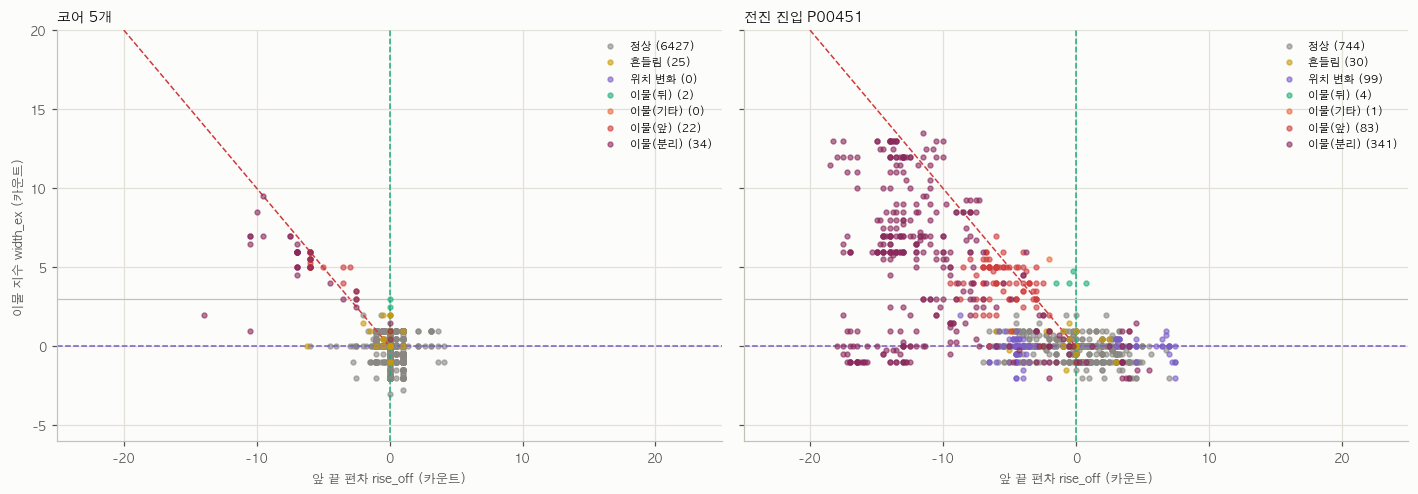

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), facecolor=SURFACE, sharey=True)
for ax, sens, ttl in [(axes[0], CORE, "코어 5개"), (axes[1], ["P00451"], "전진 진입 P00451")]:
    s = judged[judged.sensor.isin(sens)]
    for st in STATES:
        g = s[s.state == st]
        ax.scatter(g.rise_off, g.width_ex, s=10, alpha=0.6, color=STATE_COLOR[st] if st != "정상" else MUTED,
                   label=f"{st} ({len(g)})", zorder=3 if st != "정상" else 2)
    x = np.linspace(-25, 0, 2)
    ax.plot(x, -x, ls="--", color=CRITICAL, lw=1)
    ax.axhline(0, ls="--", color=PURPLE, lw=1)
    ax.axvline(0, ls="--", color=AQUA, lw=1)
    ax.axhline(W_TOL, color=AXIS, lw=0.8)
    ax.set_xlim(-25, 25)
    ax.set_ylim(-6, 20)
    ax.set_xlabel("앞 끝 편차 rise_off (카운트)", color=INK2, fontsize=8)
    ax.set_title(ttl, color=INK, fontsize=9, loc="left")
    style_ax(ax, grid="both")
    ax.legend(fontsize=7, frameon=False, loc="upper right")
axes[0].set_ylabel("이물 지수 width_ex (카운트)", color=INK2, fontsize=8)
plt.tight_layout()
plt.show()

---
## §5. 40일 판정 — 대차 × 날짜 상태

행 = 대차 ID, 열 = 가동일. 회색은 정상이다.

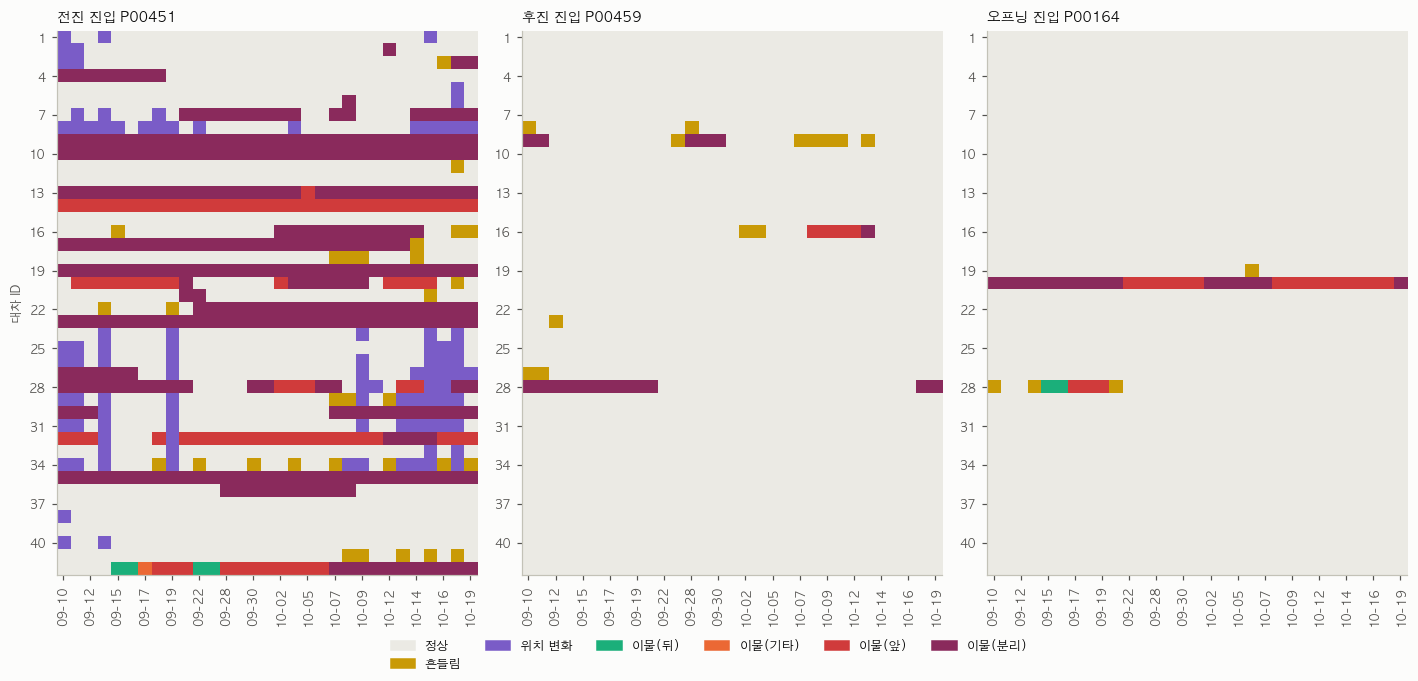

state,이름,정상,흔들림,위치 변화,이물(뒤),이물(기타),이물(앞),이물(분리)
sensor,,,,,,,,
P00140,대차 진입,1302,0,0,0,0,0,0
P00141,대차 쉬프트,1299,3,0,0,0,0,0
P00154,클로징 진입,1297,5,0,0,0,0,0
P00164,오프닝 진입,1262,4,0,2,0,18,16
P00451,전진 진입,744,30,99,4,1,83,341
P00459,후진 진입,1267,13,0,0,0,4,18


In [8]:
def state_map(ax, sensor):
    s = judged[judged.sensor == sensor]
    m = s.pivot(index="wagon", columns="day", values="state").reindex(range(1, 43))
    codes = m.apply(lambda c: c.map({k: i for i, k in enumerate(STATES)}))
    cmap = ListedColormap([STATE_COLOR[k] for k in STATES])
    ax.imshow(codes.to_numpy(dtype=float), aspect="auto", cmap=cmap,
              norm=BoundaryNorm(np.arange(-0.5, len(STATES)), len(STATES)), interpolation="nearest")
    ax.set_yticks(range(0, 42, 3), [str(w) for w in range(1, 43, 3)], fontsize=7)
    days = list(m.columns)
    ax.set_xticks(range(0, len(days), 2), [d.strftime("%m-%d") for d in days[::2]], rotation=90, fontsize=7)
    ax.set_title(f"{NAME[sensor]} {sensor}", color=INK, fontsize=9, loc="left")
    style_ax(ax, grid=None)


fig, axes = plt.subplots(1, 3, figsize=(13, 6.2), facecolor=SURFACE, gridspec_kw={"width_ratios": [1, 1, 1]})
for ax, s in zip(axes, ["P00451", "P00459", "P00164"]):
    state_map(ax, s)
axes[0].set_ylabel("대차 ID", color=INK2, fontsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLOR[k]) for k in STATES]
fig.legend(handles, STATES, ncol=6, fontsize=8, frameon=False, loc="lower center")
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

summary = judged.groupby(["sensor", "state"]).size().unstack(fill_value=0).reindex(index=ORDER, columns=STATES, fill_value=0)
summary.insert(0, "이름", [NAME[s] for s in summary.index])
summary

---
## §6. 사건 — 새 이물 · 복귀 · 위치 변화 · 승인

판정 규칙(§0-3 ②)이 만든 사건 목록. 이물 복귀에는 경고를 띄우지 않는다.

In [9]:
ev = judged[judged.event != ""]
cnt = ev.groupby(["sensor", "event"]).size().unstack(fill_value=0).reindex(ORDER).fillna(0).astype(int)
cnt.insert(0, "이름", [NAME[s] for s in cnt.index])
cnt

event,이름,새 이물,위치 변화 점검,위치 복귀,위치 승인,이물 복귀,흔들림
sensor,,,,,,,
P00140,대차 진입,0,0,0,0,0,0
P00141,대차 쉬프트,0,0,0,0,0,1
P00154,클로징 진입,0,0,0,0,0,5
P00164,오프닝 진입,2,0,0,0,0,4
P00451,전진 진입,33,60,3,9,14,25
P00459,후진 진입,5,0,0,0,4,8


In [10]:
# 코어 센서에서 생긴 사건 전부
core_ev = ev[ev.sensor.isin(CORE) & ev.event.isin(["새 이물", "이물 복귀", "위치 변화 점검", "위치 승인", "위치 복귀"])]
core_ev[["day", "sensor", "wagon", "event", "state", "rise_off", "width_ex", "fall_off", "jitter"]].round(1)

/var/folders/fj/zp006l253zsg23q736jqrh800000gn/T/ipykernel_33435/3974595675.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  core_ev[["day", "sensor", "wagon", "event", "state", "rise_off", "width_ex", "fall_off", "jitter"]].round(1)


,day,sensor,wagon,event,state,rise_off,width_ex,fall_off,jitter
4495,2026-09-10,P00164,20,새 이물,이물(분리),-7.0,6.0,-1.0,0.0
4747,2026-09-15,P00164,28,새 이물,이물(뒤),0.0,3.0,3.0,3.0
6758,2026-09-10,P00459,9,새 이물,이물(분리),-14.0,2.0,-12.0,3.5
6760,2026-09-12,P00459,9,이물 복귀,정상,-4.5,0.0,-4.5,7.0
6770,2026-09-28,P00459,9,새 이물,이물(분리),-10.5,1.0,-9.5,14.0
6773,2026-10-01,P00459,9,이물 복귀,정상,0.0,1.0,1.0,0.0
6996,2026-10-08,P00459,16,새 이물,이물(앞),-2.5,3.0,0.5,5.0
7001,2026-10-14,P00459,16,이물 복귀,정상,1.0,1.0,2.0,1.4
7347,2026-09-10,P00459,28,새 이물,이물(분리),-9.5,9.5,0.0,3.0
7357,2026-09-22,P00459,28,이물 복귀,정상,0.0,0.0,0.0,1.0


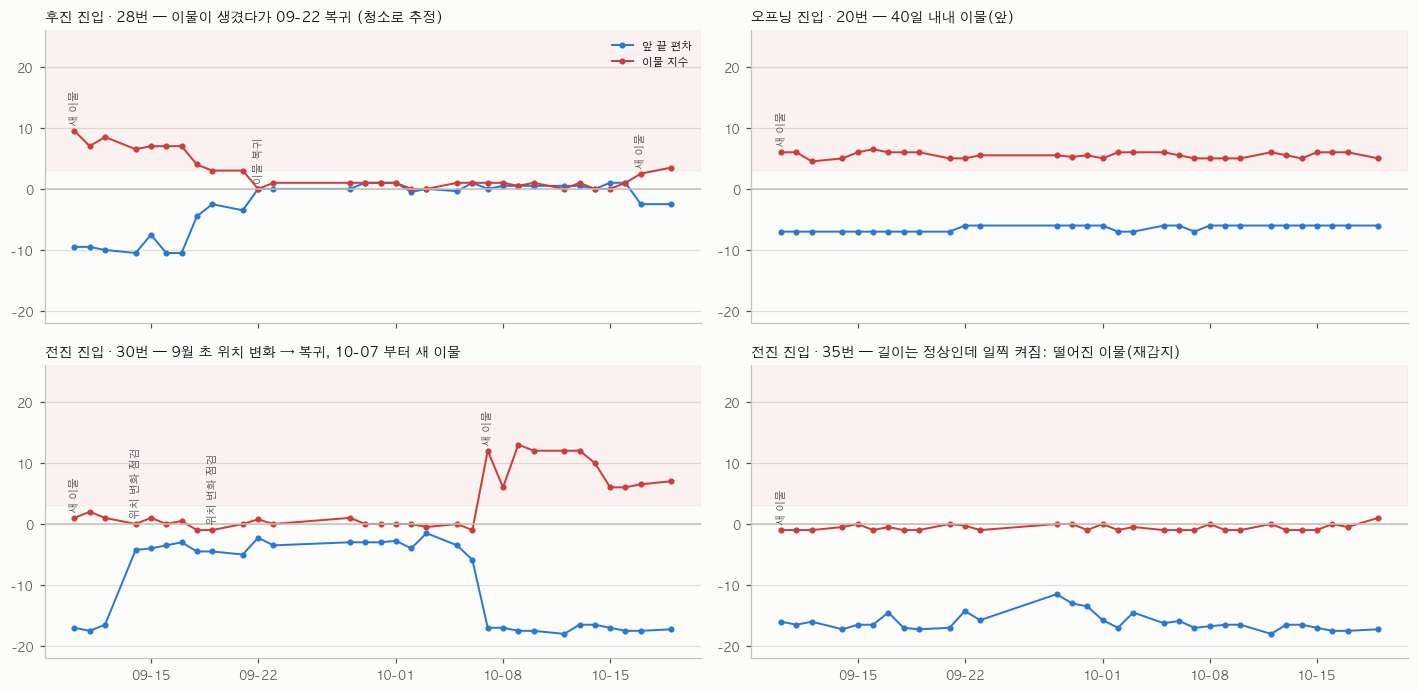

In [11]:
def track(ax, sensor, wagon, title):
    s = judged[(judged.sensor == sensor) & (judged.wagon == wagon)].sort_values("day")
    ax.plot(s.day, s.rise_off, marker="o", ms=3, lw=1.3, color=BLUE, label="앞 끝 편차")
    ax.plot(s.day, s.width_ex, marker="o", ms=3, lw=1.3, color=CRITICAL, label="이물 지수")
    ax.axhline(0, color=AXIS, lw=1)
    ax.axhspan(W_TOL, 30, color=CRITICAL, alpha=0.05)
    for _, r in s[s.event != ""].iterrows():
        ax.annotate(r.event, (r.day, max(r.width_ex, r.rise_off) + 1), fontsize=7, color=INK2, rotation=90,
                    ha="center", va="bottom")
    ax.set_ylim(-22, 26)
    ax.set_title(title, color=INK, fontsize=9, loc="left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
    style_ax(ax)


fig, axes = plt.subplots(2, 2, figsize=(13, 6.4), facecolor=SURFACE, sharex=True)
track(axes[0, 0], "P00459", 28, "후진 진입 · 28번 — 이물이 생겼다가 09-22 복귀 (청소로 추정)")
track(axes[0, 1], "P00164", 20, "오프닝 진입 · 20번 — 40일 내내 이물(앞)")
track(axes[1, 0], "P00451", 30, "전진 진입 · 30번 — 9월 초 위치 변화 → 복귀, 10-07 부터 새 이물")
track(axes[1, 1], "P00451", 35, "전진 진입 · 35번 — 길이는 정상인데 일찍 켜짐: 떨어진 이물(재감지)")
axes[0, 0].legend(fontsize=7, frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

**위치 변화가 며칠 지속되나 (N_ACCEPT 근거).** 연속으로 "위치 변화"였던 구간의 길이(가동일) 분포. 1–2일로 끝나는 짧은 변화가 많으면 n=3 이 그걸 걸러 준다.

In [12]:
runs = []
for (s, w), g in judged.sort_values("day").groupby(["sensor", "wagon"]):
    flag = (g.state == "위치 변화").to_numpy()
    k = 0
    for f in list(flag) + [False]:
        if f:
            k += 1
        elif k:
            runs.append({"sensor": s, "wagon": w, "len": k})
            k = 0
runs = pd.DataFrame(runs)
if len(runs):
    tab = runs.groupby(pd.cut(runs.len, [0, 1, 2, 3, 5, 10, 40], labels=["1일", "2일", "3일", "4–5일", "6–10일", "11일 이상"])).size()
    print(tab.to_string())

len
1일      42
2일      10
3일       4
4–5일     5


---
## §7. 센서 · 대차 · 라인 단위 — 장기 기준(09-10 – 09-19) 대비

센서 하나에서 대차 절반 이상이 같은 판정을 받은 날: 0
센서 단위 판정 (장기 기준 대비): {('P00451', '센서 재감지'): 28, ('P00451', '센서 흔들림'): 3, ('P00459', '센서 이동'): 12, ('P00459', '센서 흔들림'): 4}


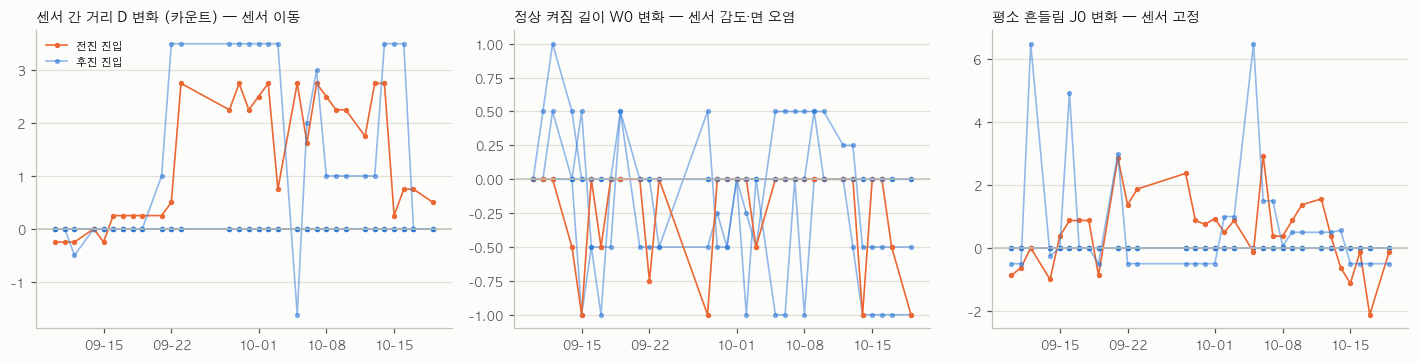

/var/folders/fj/zp006l253zsg23q736jqrh800000gn/T/ipykernel_33435/1745167164.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  flags = lv[lv.flag != ""][["day", "sensor", "flag", "D", "dD", "W0", "dW0", "J0", "dJ0"]].round(2)


,day,sensor,이름,flag,D,dD,W0,dW0,J0,dJ0
4,2026-09-10,P00451,전진 진입,센서 재감지,3751.50,-0.25,9.00,0.00,2.25,-0.88
10,2026-09-11,P00451,전진 진입,센서 재감지,3751.50,-0.25,9.00,0.00,2.50,-0.62
16,2026-09-12,P00451,전진 진입,센서 재감지,3751.50,-0.25,9.00,0.00,3.12,0.00
17,2026-09-12,P00459,후진 진입,센서 흔들림,5724.00,-0.50,9.00,1.00,7.00,6.50
22,2026-09-14,P00451,전진 진입,센서 재감지,3751.75,0.00,8.50,-0.50,2.12,-1.00
28,2026-09-15,P00451,전진 진입,센서 재감지,3751.50,-0.25,8.00,-1.00,3.50,0.38
34,2026-09-16,P00451,전진 진입,센서 재감지,3752.00,0.25,9.00,0.00,4.00,0.88
35,2026-09-16,P00459,후진 진입,센서 흔들림,5724.50,0.00,8.00,0.00,5.44,4.94
40,2026-09-17,P00451,전진 진입,센서 재감지,3752.00,0.25,8.50,-0.50,4.00,0.88
46,2026-09-18,P00451,전진 진입,센서 재감지,3752.00,0.25,9.00,0.00,4.00,0.88


In [13]:
r = judged[(judged.day >= LONG_REF[0]) & (judged.day <= LONG_REF[1])]
long_ref = r.groupby("sensor").agg(D=("D", "median"), W0=("W0", "median"), J0=("J0", "median")).reset_index()
share, lv = sensor_level(judged, long_ref)
print("센서 하나에서 대차 절반 이상이 같은 판정을 받은 날:", len(share))
print("센서 단위 판정 (장기 기준 대비):", lv[lv.flag != ""].groupby(["sensor", "flag"]).size().to_dict())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), facecolor=SURFACE, sharex=True)
for ax, col, ttl in [(axes[0], "dD", "센서 간 거리 D 변화 (카운트) — 센서 이동"),
                     (axes[1], "dW0", "정상 켜짐 길이 W0 변화 — 센서 감도·면 오염"),
                     (axes[2], "dJ0", "평소 흔들림 J0 변화 — 센서 고정")]:
    for s, g in lv.groupby("sensor"):
        ax.plot(g.day, g[col], marker="o", ms=2.5, lw=1.1, color=ORANGE if s == "P00451" else BLUE,
                alpha=1 if s == "P00451" else 0.5, label=NAME[s] if s in ("P00451", "P00459") else None)
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_title(ttl, color=INK, fontsize=9, loc="left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
    style_ax(ax)
axes[0].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.show()
flags = lv[lv.flag != ""][["day", "sensor", "flag", "D", "dD", "W0", "dW0", "J0", "dJ0"]].round(2)
flags.insert(2, "이름", flags.sensor.map(NAME))
flags

In [14]:
lr_pitch = r[r.sensor.isin(CORE)].groupby(["sensor", "wagon"]).pitch.median().reset_index()
wl = wagon_level(judged, lr_pitch, CORE)
print(f"대차 표식 이동 판정: {int(wl['표식 이동'].sum())}건 · 코어 피치 변화(대차·일 중앙값) 최대 {wl.dpitch_med.abs().max():.1f} 카운트")

stats_path = os.path.join(FEAT_DIR, "daily_ref_sensor_stats.pkl")          # conv_01 §4
sp = pd.read_pickle(stats_path)
sp = sp[(sp.sensor == "대차 진입") & (sp.resets >= 500)]
dev = (sp.speed_ratio / K_SPEED - 1) * 100
print(f"속도 비율: {sp.speed_ratio.min():.4f} – {sp.speed_ratio.max():.4f} (기준 {K_SPEED} 대비 {dev.min():+.2f}% – {dev.max():+.2f}%, 허용 ±{SPEED_TOL * 100:.1f}%)")

대차 표식 이동 판정: 0건 · 코어 피치 변화(대차·일 중앙값) 최대 1.0 카운트
속도 비율: 0.2741 – 0.2746 (기준 0.2744 대비 -0.12% – +0.07%, 허용 ±0.3%)


---
## §8. 공정 영향 — 이물이 전진 유닛 에러로 이어지나

PLC 는 P00451 이 켜지고 30카운트 뒤에 스톱퍼를 쏜다. 이물로 일찍 켜지는 대차는 스톱퍼도 그만큼 일찍 나간다.
그게 에러로 이어지는지, **원점 확인 에러**(Air_Supply2_Home_CHK_Err, 40일 중 대부분의 에러)가 언제·어느 대차에서 났는지 본다.

In [15]:
p451 = judged[judged.sensor == "P00451"][["day", "wagon", "state"]]
rows = []
for d in pd.date_range(START, END).strftime("%Y-%m-%d"):
    raw = load_group("md_fwd", d)
    if raw.empty:
        continue
    x = raw["Air_Supply2_Home_CHK_Err"].fillna(0)
    rise = raw.index[(x > 0) & (x.shift(1) == 0)]
    if not len(rise):
        continue
    ev_d = day_events(d, SENSORS.loc[["P00140", "P00451"]])
    ev_d = ev_d[ev_d.sensor == "P00451"].sort_values("t") if len(ev_d) else pd.DataFrame(columns=["t", "wagon"])
    for tt in rise:
        running = raw.Conv_Run_Out.asof(tt) > 0
        starting = (raw.loc[tt - pd.Timedelta(seconds=60):tt, "Conv_Run_Out"].fillna(0) == 0).any()
        prev = ev_d[ev_d.t <= tt].tail(1)
        rows.append({"day": pd.Timestamp(d), "t": tt, "상황": "운전 중" if running and not starting else ("기동 60초 이내" if running else "정지 중"),
                     "wagon": prev.wagon.iloc[0] if len(prev) else np.nan})
err = pd.DataFrame(rows).merge(p451, on=["day", "wagon"], how="left")
print(err["상황"].value_counts().to_string())
err[err["상황"] == "운전 중"][["t", "wagon", "state"]]

상황
정지 중         93
운전 중          3
기동 60초 이내     1


,t,wagon,state
53,2026-09-30 11:00:53.929316,34.0,흔들림
61,2026-10-04 00:13:56.536799,NaN,NaN
78,2026-10-16 19:44:52.285694,37.0,정상


---
## §9. 정리

**코어 기준 격자**
- 코어 센서는 대차 진입·쉬프트·클로징·오프닝·후진 진입 5개다 (§3, 한 주 기준).
  - 대차 간 위치 차이 std 0 – 1.0, 켜짐 길이 차이 0.55 – 1.08, 대차 안 흔들림 0 – 0.5 카운트.
  - 전진 진입은 위치 차이 5.95, 길이 차이 2.89, 흔들림 3.5 로 코어가 아니다.
- 대차 ID 는 그 대차가 P00140 을 지날 때의 메인 대차번호, 즉 **PLC 대차번호**다. 1번 대차 감지 센서 세 개로 센서별 칸 수(n_back)를 검증했고, 31 가동일 내내 같았다.
- 루프 지도 (P00140 기준 같은 대차까지 카운트): 쉬프트 19 · 클로징 295 · 오프닝 3,709 · 전진 3,751 · 후진 5,726. 한 바퀴는 약 5,850.

**판정 규칙이 40일에서 한 일**

| 대상 | 판정 | 해석 |
|---|---|---|
| 전진 진입 | 새 이물 33 · 이물 복귀 14 · 위치 변화 점검 60 → 승인 9 · 위치 복귀 3. 센서 단위 "재감지"가 거의 매일 | 이물이 생기고 사라지기를 반복한다. 복귀에는 경고가 없다. 위치 변화 61건 중 52건은 1 – 2일에 끝나서 n=3 이 걸러 준다 |
| 전진 진입 · 대차별 이물 비율 (31 가동일) | **지속:** 9 · 10 · 13 · 14 · 19 · 23 · 35번 100%, 42번 87%, 32번 84%. **새로 생김:** 22번(처음 7일 0% → 최근 7일 100%), 7번(0 → 71%), 30번(43 → 100%). **사라짐:** 4번(100 → 0%), 27번(86 → 0%), 17번(100 → 29%) | 점검 추천 목록. 사라진 대차는 청소로 보인다 |
| 후진 진입 · 28번 | 09-10 이물(재감지, 9카운트 일찍, 길이 +9) → **09-22 복귀** → 10-17 다시 이물 | 청소로 보이는 복귀를 경고 없이 처리했다 |
| 오프닝 진입 · 20번 | 40일 내내 이물(앞) 6카운트 | **코어 센서에서 나온 유일한 지속 이물** → 점검 1순위 |
| 후진 진입 센서 | 위치 0 → +3.5(09-22) → +1(10-08) → +3.5(10-14) → 0(10-17), 흔들림 큰 날 09-12 · 09-16 · 10-05 | **센서 브래킷이 헐거운 모습** → 고정 점검 |
| 대차 표식 · 라인 | 이동 0건, 속도 비율 정상 | 이상 없음 |

**공정 영향:** 전진 유닛 원점 확인 에러 97회 중 93회는 정지 중에 났다(기동 시도 때 걸리는 에러). 운전 중 3회도 이물 대차와 무관했다. 지금 수준의 이물은 공정 에러로 이어지지 않으므로 **경고가 아니라 "점검 추천"** 으로 보여준다. 에러와 연결되는 이물 수준이 나오면 그때 경고 기준을 정한다.

**현장에 확인할 것 (우선순위)**
1. 오프닝 진입 센서 앞을 지나는 **20번 대차** — 표식 앞에 무엇이 있는지
2. **후진 진입 센서 브래킷** 고정 상태
3. 전진 진입 센서 앞을 지나는 **9 · 10 · 13 · 14 · 19 · 23 · 35번 대차**(지속), 22 · 7 · 30번(최근 생김) — 표식 앞에 떨어져 있는 무엇에 한 번 더 켜지는지. 생겼다 사라지기도 하므로(4 · 27 · 17번) 찌꺼기일 가능성이 크다. 센서 감지 거리가 다른 센서보다 길게 잡혀 있는지도 함께 확인
4. 09-22 무렵 후진 센서 주변 작업(청소·재설치) 이력 — 28번 복귀와 센서 위치 이동이 같은 날이다

현장 답을 받으면 규칙 기준값(§0-4)을 다듬고, 그게 첫 라벨이 된다.

**다음 (conv_03):** 이 격자 위에 유닛 내부 시퀀스를 얹는다. 전진·후진 유닛의 스톱퍼·노즐·복귀, 오프닝·클로징 리프트의 감속·정지 리밋을 다룬다. 시퀀스는 두 가지 자로 같이 잰다 — 트리거 기준(유닛 기계 상태), 격자 기준(대차 위 위치).